# P4 — Query Rewriting for RAG
## HyDE, Query2doc, and LLM-based Rewriting on NQ Open

**Author:** Sacha Frankhauser — 346608

---

### Motivation

Study whether transforming the query before retrieval, i.e. modifying only the input fed to the retriever, keeping everything else identical to the shared baseline, closes the semantic gap that is due to short/bad queries. Three families of methods are evaluated:

| Method | Idea | Reference |
|---|---|---|
| **HyDE** | Generator LLM (here Mistral-7B-Instruct-v0.2) writes a hypothetical Wikipedia passage; its embedding replaces the query | Gao et al. 2022 |
| **Query2doc** | 4-shot LLM pseudo-doc concatenated with the original query | Wang et al. 2023 |
| **Rewrite** | LLM rewrites the question into a search-engine-friendly query | Ma et al. 2023 |

All three differ only in **what is sent to the retriever**. The embedder, the FAISS index, the generator, the reader prompt, the evaluation slice, and the metrics are identical to `code/baseline/`.

### Architecture — shared scripts + vLLM + project-specific package

| Source | Provides |
|---|---|
| `code/baseline/retriever.py` | `Retriever` (`contriever-msmarco` + FAISS) |
| `code/baseline/evaluate.py` | `evaluate`, `print_metrics` — shared EM / ROUGE-L / F1 / hit-rate |
| `code/p4_querystage/vllm_runner.py` | `VLLMRunner` — Mistral-7B-Instruct-v0.2 via vLLM (batched) |
| `code/p4_querystage/query_transforms.py` | `transform_hyde`, `transform_query2doc`, `transform_rewrite`, `transform_hyde_avg` |
| `code/p4_querystage/pipeline_p4.py` | `run_method` — full retrieve-then-read for one method |
| `code/p4_querystage/bias_analysis.py` | `feature_score_correlations` (Goyal et al. 2026), `retrieved_chunk_stats` |

The shared `Generator` from `code/baseline/generator.py` uses HF transformers (`model.generate`). For P4 we need to generate at two stages per query (transform + answer) on hundreds of questions plus ablations, so the reader prompt is the same shape as the baseline `Generator.build_prompt`, but inference uses vLLM for speed. The score deltas we report are therefore attributable to the retrieval stage alone.

### Shared Baseline (unchanged across methods)

| Component | Choice |
|---|---|
| Dataset | `nq_open` validation (offset 0, first `N_QUESTIONS`) |
| Embedder | `facebook/contriever-msmarco` (`SentenceTransformer`) |
| Vector Store | `faiss.IndexFlatIP` + L2-normalised vectors (= cosine) |
| Pre-built Index | `/scratch/faiss_index/baseline` (no rebuild) |
| Generator | `mistralai/Mistral-7B-Instruct-v0.2` via vLLM |
| Reader prompt | Same shape as `code/baseline/generator.py` |
| `top-k` | 5 |

---
## 0 · Environment Setup


In [1]:
!pip install -q pandas tqdm rouge-score

In [ ]:
import os
import sys
import json
from pathlib import Path

# ─ Project paths
# Notebook lives in `notebooks/`, so the repo root is one level up.
REPO_ROOT     = Path('..').resolve()
BASELINE_DIR  = REPO_ROOT / 'code' / 'baseline'
P4_DIR        = REPO_ROOT / 'code' / 'p4_querystage'

# Order matters for vLLM (vllm_runner must be importable BEFORE retriever).
sys.path.insert(0, str(BASELINE_DIR))
sys.path.insert(0, str(P4_DIR))

SCRATCH        = Path('/scratch')
HF_HOME        = SCRATCH / 'hf_cache'
INDEX_DIR      = SCRATCH / 'faiss_index' / 'baseline'           # baseline FAISS index
RESULTS_DIR    = SCRATCH / 'results' / 'p4'                     # P4 results in JSONs format
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# IMPORTANT: must run BEFORE `from datasets import load_dataset`, because
# the datasets library reads HF_HOME at import time.
os.environ.setdefault('HF_HOME',            str(HF_HOME))
os.environ.setdefault('HF_DATASETS_CACHE',  str(HF_HOME / 'datasets'))
os.environ.setdefault('TRANSFORMERS_CACHE', str(HF_HOME / 'transformers'))

# ─ Experiment knobs
N_QUESTIONS  = 100   # NQ Open validation slice; matches the shared baseline default
TOP_K        = 5     # retrieved chunks per query
GENERATOR    = 'mistralai/Mistral-7B-Instruct-v0.2'

print(f'REPO_ROOT  : {REPO_ROOT}')
print(f'INDEX_DIR  : {INDEX_DIR}        (exists={INDEX_DIR.exists()})')
print(f'RESULTS_DIR: {RESULTS_DIR}')
print(f'HF_HOME    : {os.environ["HF_HOME"]}')
print(f'N_QUESTIONS: {N_QUESTIONS}   TOP_K: {TOP_K}')

REPO_ROOT  : /scratch/open-project-m2-mnlp212
INDEX_DIR  : /scratch/faiss_index/baseline        (exists=True)
RESULTS_DIR: /scratch/results/p4
HF_HOME    : /scratch/hf_cache
N_QUESTIONS: 100   TOP_K: 5


---
## 1 · Generator — Mistral-7B-Instruct-v0.2 via vLLM

> **Important — vLLM must be initialised _before_ any other CUDA call.**  
> Loading the SentenceTransformer (= the retriever) first triggers a CUDA multiprocessing conflict

`VLLMRunner` is a thin wrapper around `vllm.LLM` defined in `code/p4_querystage/vllm_runner.py`. It exposes:
- `to_chat(prompt)` — wraps user prompts with Mistral's `[INST] ... [/INST]` tags via `apply_chat_template`
- `generate(prompts, sampling)` — batched generation, returns one completion per prompt
- `generate_n_samples(prompts, sampling, n)` — batched generation, N completions per prompt (used for the HyDE multi-sample ablation)

We allocate 55% of GPU memory to vLLM, leaving headroom for the contriever encoder on the same A100.

In [ ]:
from vllm_runner import VLLMRunner

llm = VLLMRunner(
    model_name=GENERATOR,
    dtype='float16',
    gpu_memory_utilization=0.55,
    max_model_len=4096,
    download_dir=str(HF_HOME),
)

/usr/local/lib/python3.12/dist-packages/transformers/utils/hub.py:110: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


INFO 05-17 07:19:12 [__init__.py:216] Automatically detected platform cuda.
Loading vLLM generator: mistralai/Mistral-7B-Instruct-v0.2
INFO 05-17 07:19:15 [utils.py:233] non-default args: {'download_dir': '/scratch/hf_cache', 'dtype': 'float16', 'max_model_len': 4096, 'gpu_memory_utilization': 0.55, 'disable_log_stats': True, 'model': 'mistralai/Mistral-7B-Instruct-v0.2'}
INFO 05-17 07:19:16 [model.py:547] Resolved architecture: MistralForCausalLM


`torch_dtype` is deprecated! Use `dtype` instead!


WARNING 05-17 07:19:16 [model.py:1733] Casting torch.bfloat16 to torch.float16.
INFO 05-17 07:19:16 [model.py:1510] Using max model len 4096
INFO 05-17 07:19:21 [scheduler.py:205] Chunked prefill is enabled with max_num_batched_tokens=8192.


/usr/local/lib/python3.12/dist-packages/vllm/transformers_utils/tokenizer.py:286: FutureWarning: It is strongly recommended to run mistral models with `--tokenizer-mode "mistral"` to ensure correct encoding and decoding.
  return get_tokenizer(


(EngineCore_DP0 pid=6418) INFO 05-17 07:19:22 [core.py:644] Waiting for init message from front-end.
(EngineCore_DP0 pid=6418) INFO 05-17 07:19:22 [core.py:77] Initializing a V1 LLM engine (v0.11.0) with config: model='mistralai/Mistral-7B-Instruct-v0.2', speculative_config=None, tokenizer='mistralai/Mistral-7B-Instruct-v0.2', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=False, dtype=torch.float16, max_seq_len=4096, download_dir='/scratch/hf_cache', load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, disable_custom_all_reduce=False, quantization=None, enforce_eager=False, kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_fallback=False, disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser=''), observability_config=ObservabilityConfig(show_hidden_metrics_for_version=None, otlp_traces_endpoint=No

... (4 outputs left out)

Capturing CUDA graphs (mixed prefill-decode, PIECEWISE): 100%|██████████| 67/67 [00:03<00:00, 19.74it/s]
Capturing CUDA graphs (decode, FULL): 100%|██████████| 35/35 [00:01<00:00, 21.85it/s]


(EngineCore_DP0 pid=6418) INFO 05-17 07:19:48 [gpu_model_runner.py:3480] Graph capturing finished in 6 secs, took 0.61 GiB
(EngineCore_DP0 pid=6418) INFO 05-17 07:19:48 [core.py:210] init engine (profile, create kv cache, warmup model) took 15.91 seconds


(EngineCore_DP0 pid=6418) /usr/local/lib/python3.12/dist-packages/vllm/transformers_utils/tokenizer.py:286: FutureWarning: It is strongly recommended to run mistral models with `--tokenizer-mode "mistral"` to ensure correct encoding and decoding.
(EngineCore_DP0 pid=6418)   return get_tokenizer(


INFO 05-17 07:19:49 [llm.py:306] Supported_tasks: ['generate']
vLLM ready.


---
## 2 · Retriever — `facebook/contriever-msmarco` + pre-built FAISS index

We use the `Retriever` class from `code/baseline/retriever.py` without modification. The index has already been built on the cluster (200k Wikipedia articles, token-level chunking) and lives at `/scratch/faiss_index/baseline`, so the only thing this cell does is `load_index()`.

Contriever is **symmetric**: queries and passages share the same encoder, so the embedding of a hypothetical document (HyDE) or an expanded query (Query2doc) lands in the same space as the indexed chunks; no prefix engineering needed.

In [ ]:
from retriever import Retriever       

retriever = Retriever()             
retriever.load_index(str(INDEX_DIR))
print(f'FAISS index loaded: {retriever.index.ntotal:,} vectors, dim={retriever.index.d}')

Loading retriever model: facebook/contriever-msmarco


config.json:   0%|          | 0.00/619 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/321 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Index loaded from /scratch/faiss_index/baseline with 205264 vectors
FAISS index loaded: 205,264 vectors, dim=768


---
## 3 · Dataset — NQ Open (validation)

We evaluate on the first `N_QUESTIONS` examples of the NQ Open validation split, i.e the same slicing convention as `code/baseline/pipeline.py`, so our numbers are directly comparable to the baseline and to P1 / P2 / P3 runs.

In [5]:
from datasets import load_dataset

nq_open = load_dataset('nq_open', split='validation')
eval_examples = nq_open.select(range(N_QUESTIONS))
print(f'NQ Open validation slice: {len(eval_examples)} examples\n')

for i in range(3):
    ex = eval_examples[i]
    print(f'[{i}] Q: {ex["question"]}')
    print(f'    A: {ex["answer"]}\n')

NQ Open validation slice: 100 examples

[0] Q: when was the last time anyone was on the moon
    A: ['14 December 1972 UTC', 'December 1972']

[1] Q: who wrote he ain't heavy he's my brother lyrics
    A: ['Bobby Scott', 'Bob Russell']

[2] Q: how many seasons of the bastard executioner are there
    A: ['one', 'one season']



---
## 4 · Method runner

`pipeline_p4.run_method` runs one P4 method end-to-end on `eval_examples`:

1. **Query transform**: dispatches to the appropriate function in `query_transforms.py` (baseline = identity, HyDE = generate pseudo-doc, Query2doc = generate + concat, Rewrite = LLM rewrite).
2. **Retrieval**: batched FAISS search via `retrieval_utils.retrieve_by_text` (or `retrieve_by_embedding` for the HyDE-averaging ablation).
3. **Reader**: batched answer generation via vLLM with the shared reader prompt.
4. Returns per-query records compatible with `evaluate.evaluate`.

The thin helper below runs one method, scores it with the shared metrics, and saves to `/scratch/results/p4/`.

In [ ]:
from pipeline_p4 import run_method
from evaluate import evaluate, print_metrics    # code/baseline/evaluate.py

def run_and_score(method, label=None, **kwargs):
    """Run one P4 method, score it with the shared metrics.

    Args:
        method: must be one of {baseline, hyde, query2doc, rewrite}.
                Anything else raises `ValueError: Unknown method: ...` inside
                pipeline_p4.transform_queries.
        label:  filename suffix (defaults to `method`). Use a distinct label for
                ablation runs to avoid overwriting the canonical per-method JSON.
    """
    label = label or method
    records = run_method(
        method, llm, retriever, eval_examples,
        k=TOP_K, **kwargs,
    )
    metrics = evaluate(records)
    print_metrics(metrics, label=f'P4 — {label}')
    out_path = RESULTS_DIR / f'p4_{label}.json'
    with open(out_path, 'w') as f:
        json.dump({'method': method, 'label': label, 'metrics': metrics,
                   'records': records, 'kwargs': kwargs,
                   'n_questions': N_QUESTIONS, 'k': TOP_K}, f, indent=2)
    print(f'  saved → {out_path}')
    return records, metrics

---
## 5 · Baseline RAG (no query transformation)

Sanity check: with the shared baseline behaviour (raw question → contriever → FAISS → Mistral), we should reproduce the baseline numbers. This is the reference point against which we measure HyDE / Query2doc / Rewrite.

In [7]:
baseline_records, baseline_metrics = run_and_score('baseline')


[baseline] Query-stage transform on 100 questions...
[baseline] FAISS search...
[baseline] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


P4 — baseline
Exact Match:        0.0500
ROUGE-L:            0.1247
Token F1:           0.1204
Retrieval Hit Rate: 0.3500
Samples:            100

  saved → /scratch/results/p4/p4_baseline.json


---
## 6 · HyDE — Hypothetical Document Embeddings (Gao et al. 2022)

**Idea.** The LLM writes a *hypothetical* Wikipedia-style passage that would answer the question (T=0.7, as in the paper). Its embedding *replaces* the query: it lands in the same dense space as the indexed chunks (contriever is symmetric), and the inner product against the FAISS index picks the *real* document with the closest semantics.

**Why this should help.** A short factoid question has weak overlap with the long Wikipedia passage that answers it. The hypothetical passage shares topic, vocabulary, and named entities with the real passage, even when it gets some facts wrong.

In [8]:
hyde_records, hyde_metrics = run_and_score('hyde', hyde_temperature=0.7)


[hyde] Query-stage transform on 100 questions...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

[hyde] FAISS search...
[hyde] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


P4 — hyde
Exact Match:        0.0800
ROUGE-L:            0.1679
Token F1:           0.1692
Retrieval Hit Rate: 0.3900
Samples:            100

  saved → /scratch/results/p4/p4_hyde.json


In [9]:
# Inspect the first HyDE pseudo-document — what is actually fed to the retriever
ex = hyde_records[0]
print(f'Question         : {ex["question"]}')
print(f'Gold answer(s)   : {ex["gold_answers"]}')
print(f'\nHyDE pseudo-doc  :\n{ex["intermediate"]}')
print(f'\nTop-1 retrieved  :\n{ex["chunks"][0][:400]}...')
print(f'\nFinal prediction : {ex["prediction"]}')

Question         : when was the last time anyone was on the moon
Gold answer(s)   : ['14 December 1972 UTC', 'December 1972']

HyDE pseudo-doc  :
The last manned moon landing was on December 14, 2004, when NASA's Apollo 17 mission ended with the safe return of astronauts Gene Cernan and Harrison Schmitt to Earth. Since then, all lunar exploration has been conducted by unmanned spacecraft. The most recent unmanned moon landing was by China's Chang'e 5 mission on December 17, 2020, which returned lunar samples to Earth for the first time since the Apollo missions.

Top-1 retrieved  :
Apollo 17 (December 7–19, 1972) was the eleventh and final mission of NASA's Apollo program, the sixth and most recent time humans have set foot on the Moon or traveled beyond low Earth orbit. Commander Gene Cernan and Lunar Module Pilot Harrison Schmitt walked on the Moon, while Command Module Pilot Ronald Evans orbited above. Schmitt was the only professional geologist to land on the Moon; he wa...

Final 

---
## 7 · Query2doc — Query Expansion with LLM Pseudo-Documents (Wang et al. 2023)

**Idea.** Same generator as HyDE, but the pseudo-doc is concatenated with the original query rather than replacing it: `q [SEP] d'`.

**Prompt.** 4-shot, with NQ-style examples we wrote in `prompts.py` (the paper's MS-MARCO examples are off-domain for NQ). Sampling temperature = 1.0, as recommended.

In [10]:
q2d_records, q2d_metrics = run_and_score('query2doc', q2d_repeat=1)


[query2doc] Query-stage transform on 100 questions...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

[query2doc] FAISS search...
[query2doc] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


P4 — query2doc
Exact Match:        0.0700
ROUGE-L:            0.1470
Token F1:           0.1436
Retrieval Hit Rate: 0.3500
Samples:            100

  saved → /scratch/results/p4/p4_query2doc.json


In [11]:
# Inspect the first Query2doc output
ex = q2d_records[0]
print(f'Question              : {ex["question"]}')
print(f'Gold answer(s)        : {ex["gold_answers"]}')
print(f'\nGenerated pseudo-doc  :\n{ex["intermediate"]}')
print(f'\nTop-1 retrieved chunk :\n{ex["chunks"][0][:400]}...')
print(f'\nFinal prediction      : {ex["prediction"]}')

Question              : when was the last time anyone was on the moon
Gold answer(s)        : ['14 December 1972 UTC', 'December 1972']

Generated pseudo-doc  :
The last manned moon landing occurred on 11 December 2004, when the Apollo 17 mission's crew, consisting of Eugene Cernan and Harrison Schmitt, spent three days exploring the lunar surface and collecting samples before returning to Earth. Since then, only unmanned spacecraft have reached the moon.

Top-1 retrieved chunk :
Apollo 17 (December 7–19, 1972) was the eleventh and final mission of NASA's Apollo program, the sixth and most recent time humans have set foot on the Moon or traveled beyond low Earth orbit. Commander Gene Cernan and Lunar Module Pilot Harrison Schmitt walked on the Moon, while Command Module Pilot Ronald Evans orbited above. Schmitt was the only professional geologist to land on the Moon; he wa...

Final prediction      : December 7, 1972


---
## 8 · Query Rewriting (Ma et al. 2023, single-query variant)

**Idea.** Ask the LLM to rewrite the question into a single search-engine-friendly query (3-shot, deterministic decoding). Unlike HyDE / Query2doc, this produces a **short** retrieval query, it changes the surface form of the question rather than expanding it.

In [12]:
rw_records, rw_metrics = run_and_score('rewrite')


[rewrite] Query-stage transform on 100 questions...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

[rewrite] FAISS search...
[rewrite] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


P4 — rewrite
Exact Match:        0.0500
ROUGE-L:            0.1554
Token F1:           0.1580
Retrieval Hit Rate: 0.3300
Samples:            100

  saved → /scratch/results/p4/p4_rewrite.json


In [13]:
# Show a handful of question → rewrite pairs
print(f'{"original":<55s}  →  rewritten')
print('-' * 110)
for r in rw_records[:8]:
    print(f'{r["question"][:55]:<55s}  →  {r["intermediate"]}')

original                                                 →  rewritten
--------------------------------------------------------------------------------------------------------------
when was the last time anyone was on the moon            →  last moon landing date
who wrote he ain't heavy he's my brother lyrics          →  Who wrote the lyrics to 'He Ain't Heavy, He's My Brother
how many seasons of the bastard executioner are there    →  number of seasons The Bastard Executioner
when did the eagles win last super bowl                  →  last Super Bowl win by Philadelphia Eagles
who won last year's ncaa women's basketball              →  Last year's NCAA Women's Basketball champion
when did the isle of wight become an island              →  When did Isle of Wight form as an island?
love yourself by justin bieber is about who              →  Love Yourself" by Justin Bieber lyrics meaning
who was the ruler of england in 1616                     →  Ruler of England in 1616


---
## 9 · Comparison Table — main results

All four methods share retriever, generator, reader prompt, NQ slice, and `top_k`. The only thing that varies is what is sent to the retriever, so any metric delta is attributable to the query-stage transformation.

In [14]:
import pandas as pd

all_metrics = {
    'Baseline':  baseline_metrics,
    'HyDE':      hyde_metrics,
    'Query2doc': q2d_metrics,
    'Rewrite':   rw_metrics,
}
rows = []
for name, m in all_metrics.items():
    base = baseline_metrics
    rows.append({
        'Method':        name,
        'EM':            f'{m["exact_match"]:.4f}',
        'Δ EM':          f'{m["exact_match"] - base["exact_match"]:+.4f}'  if name != 'Baseline' else '—',
        'ROUGE-L':       f'{m["rouge_l"]:.4f}',
        'Δ ROUGE-L':     f'{m["rouge_l"] - base["rouge_l"]:+.4f}'          if name != 'Baseline' else '—',
        'Token F1':      f'{m["token_f1"]:.4f}',
        'Hit-rate':      f'{m["retrieval_hit_rate"]:.4f}',
        'Δ Hit-rate':    f'{m["retrieval_hit_rate"] - base["retrieval_hit_rate"]:+.4f}' if name != 'Baseline' else '—',
        'N':             m['n_samples'],
    })
df = pd.DataFrame(rows).set_index('Method')
df

,EM,Δ EM,ROUGE-L,Δ ROUGE-L,Token F1,Hit-rate,Δ Hit-rate,N
Method,,,,,,,,
Baseline,0.0500,—,0.1247,—,0.1204,0.3500,—,100
HyDE,0.0800,+0.0300,0.1679,+0.0432,0.1692,0.3900,+0.0400,100
Query2doc,0.0700,+0.0200,0.1470,+0.0223,0.1436,0.3500,+0.0000,100
Rewrite,0.0500,+0.0000,0.1554,+0.0307,0.1580,0.3300,-0.0200,100


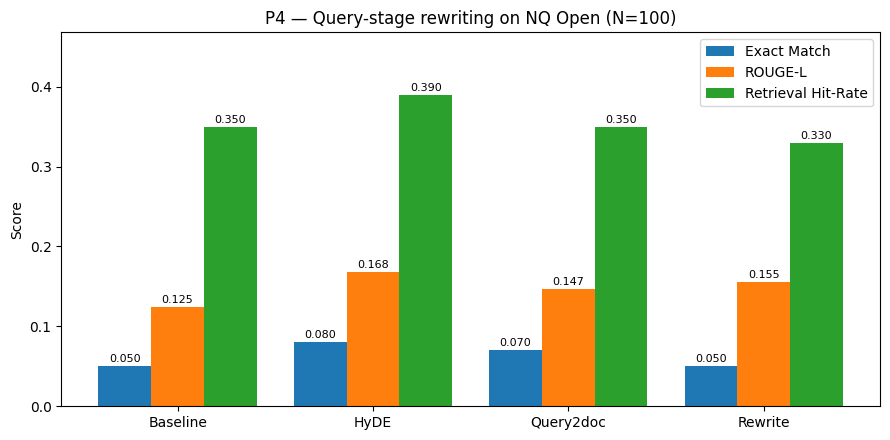

In [15]:
# Bar chart for the three retrieval-aware metrics (EM, ROUGE-L, hit-rate)
import matplotlib.pyplot as plt
import numpy as np

names   = list(all_metrics.keys())
em      = [all_metrics[n]['exact_match']        for n in names]
rouge   = [all_metrics[n]['rouge_l']            for n in names]
hit     = [all_metrics[n]['retrieval_hit_rate'] for n in names]
x = np.arange(len(names))
w = 0.27

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, em,    width=w, label='Exact Match')
ax.bar(x,     rouge, width=w, label='ROUGE-L')
ax.bar(x + w, hit,   width=w, label='Retrieval Hit-Rate')
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylabel('Score'); ax.set_ylim(0, max(max(em), max(rouge), max(hit)) * 1.2)
ax.set_title(f'P4 — Query-stage rewriting on NQ Open (N={N_QUESTIONS})')
ax.legend()
for i, (a, b, c) in enumerate(zip(em, rouge, hit)):
    ax.text(i - w, a + 0.005, f'{a:.3f}', ha='center', fontsize=8)
    ax.text(i,     b + 0.005, f'{b:.3f}', ha='center', fontsize=8)
    ax.text(i + w, c + 0.005, f'{c:.3f}', ha='center', fontsize=8)
plt.tight_layout(); plt.show()

---
## 10 · Ablations

### 10.1 HyDE — number of hypothetical-document samples (Eq. 6 of Gao et al. 2022)

Gao et al. propose to sample N pseudo-docs at T=0.7 and average their embeddings. Each individual pseudo-doc may hallucinate, but the average vector concentrates on what the LLM is consistently certain about. We sweep N ∈ {1, 4, 8}, with and without the original query embedding added to the average.

In [18]:
hyde_ablation = {}

# With the original query embedding included in the average (Eq. 8 of Gao et al.)
for n in (1, 4, 8):
    print(f'\n── HyDE N={n}, +query embedding ───────────────────────────────────')
    _, m = run_and_score(
        method='hyde',                       # dispatch key (valid for run_method)
        label=f'hyde_n{n}_wq',                # distinct filename per ablation run
        hyde_n_samples=n,
        hyde_include_query=True,
    )
    hyde_ablation[(n, True)] = m

# Without the query embedding in the average (Eq. 7 of Gao et al.)
for n in (4, 8):
    print(f'\n── HyDE N={n}, no query embedding ─────────────────────────────────')
    _, m = run_and_score(
        method='hyde',
        label=f'hyde_n{n}_noq',
        hyde_n_samples=n,
        hyde_include_query=False,
    )
    hyde_ablation[(n, False)] = m


── HyDE N=1, +query embedding ───────────────────────────────────

[hyde] Query-stage transform on 100 questions...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

[hyde] FAISS search...
[hyde] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

... (21 outputs left out)

[hyde] FAISS search...
[hyde] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


P4 — hyde_n8_noq
Exact Match:        0.0800
ROUGE-L:            0.1564
Token F1:           0.1571
Retrieval Hit Rate: 0.3900
Samples:            100

  saved → /scratch/results/p4/p4_hyde_n8_noq.json


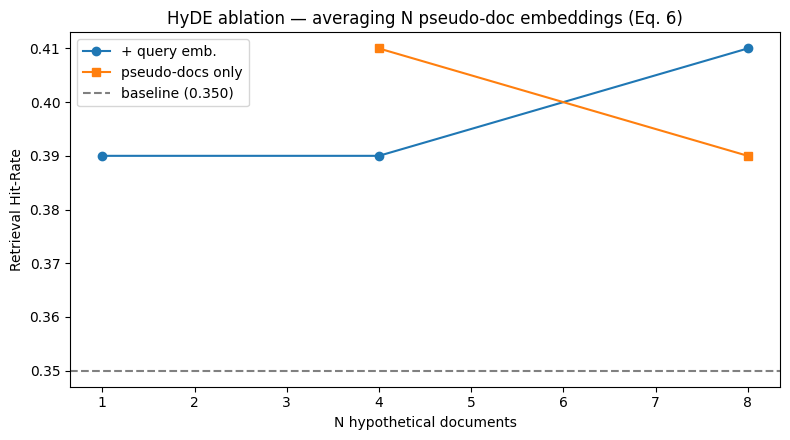

In [19]:
# Plot the HyDE ablation
fig, ax = plt.subplots(figsize=(8, 4.5))
for include_query, marker, label in [(True, 'o', '+ query emb.'), (False, 's', 'pseudo-docs only')]:
    pts = [(n, hyde_ablation[(n, include_query)]['retrieval_hit_rate'])
           for n in (1, 4, 8) if (n, include_query) in hyde_ablation]
    if pts:
        xs, ys = zip(*pts)
        ax.plot(xs, ys, marker=marker, label=label)
ax.axhline(baseline_metrics['retrieval_hit_rate'], ls='--', color='gray',
           label=f'baseline ({baseline_metrics["retrieval_hit_rate"]:.3f})')
ax.set_xlabel('N hypothetical documents');  ax.set_ylabel('Retrieval Hit-Rate')
ax.set_title('HyDE ablation — averaging N pseudo-doc embeddings (Eq. 6)')
ax.legend(); plt.tight_layout(); plt.show()

### 10.2 Query2doc — query-repetition factor

Wang et al. 2023 repeat the query `n` times before concatenating with the pseudo-doc, to keep BM25 term weights balanced (Eq. 1 of the paper). The paper recommends `n=5` for sparse retrieval and `n=1` for dense. We test this empirically on contriever: sweeping `n ∈ {1, 3, 5}`.

In [20]:
q2d_ablation = {}
for rep in (1, 3, 5):
    print(f'\n── Query2doc repeat_n={rep} ────────────────────────────────────────')
    _, m = run_and_score(
        method='query2doc',
        label=f'query2doc_rep{rep}',
        q2d_repeat=rep,
    )
    q2d_ablation[rep] = m

rep_df = pd.DataFrame([
    {'repeat_n': k,
     'EM': v['exact_match'], 'ROUGE-L': v['rouge_l'],
     'Hit-rate': v['retrieval_hit_rate']}
    for k, v in q2d_ablation.items()
]).set_index('repeat_n')
rep_df


── Query2doc repeat_n=1 ────────────────────────────────────────

[query2doc] Query-stage transform on 100 questions...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

[query2doc] FAISS search...
[query2doc] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

... (10 outputs left out)

Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


P4 — query2doc_rep5
Exact Match:        0.0500
ROUGE-L:            0.1441
Token F1:           0.1428
Retrieval Hit Rate: 0.4100
Samples:            100

  saved → /scratch/results/p4/p4_query2doc_rep5.json


,EM,ROUGE-L,Hit-rate
repeat_n,,,
1,0.05,0.1417,0.42
3,0.05,0.1319,0.37
5,0.05,0.1441,0.41


### 10.3 `top_k` sweep — does query rewriting trade off precision vs. recall?

If a method improves the retrieval signal, hit-rate should rise faster with the number of retrieved documents `k` than the baseline. We sweep `k ∈ {1, 3, 5, 10}` on Baseline vs. HyDE vs. Query2doc.

In [22]:
topk_grid = {}
for method in ('baseline', 'hyde', 'query2doc'):
    for k in (1, 3, 5, 7):
        print(f'\n── {method}, k={k} ─────────────────────────────────────────────')
        recs = run_method(method, llm, retriever, eval_examples, k=k)
        topk_grid[(method, k)] = evaluate(recs)


── baseline, k=1 ─────────────────────────────────────────────

[baseline] Query-stage transform on 100 questions...
[baseline] FAISS search...
[baseline] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/113 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


── baseline, k=3 ─────────────────────────────────────────────

[baseline] Query-stage transform on 100 questions...
[baseline] FAISS search...
[baseline] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

... (50 outputs left out)

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

[query2doc] FAISS search...
[query2doc] Reader generation...


Adding requests:   0%|          | 0/100 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/100 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

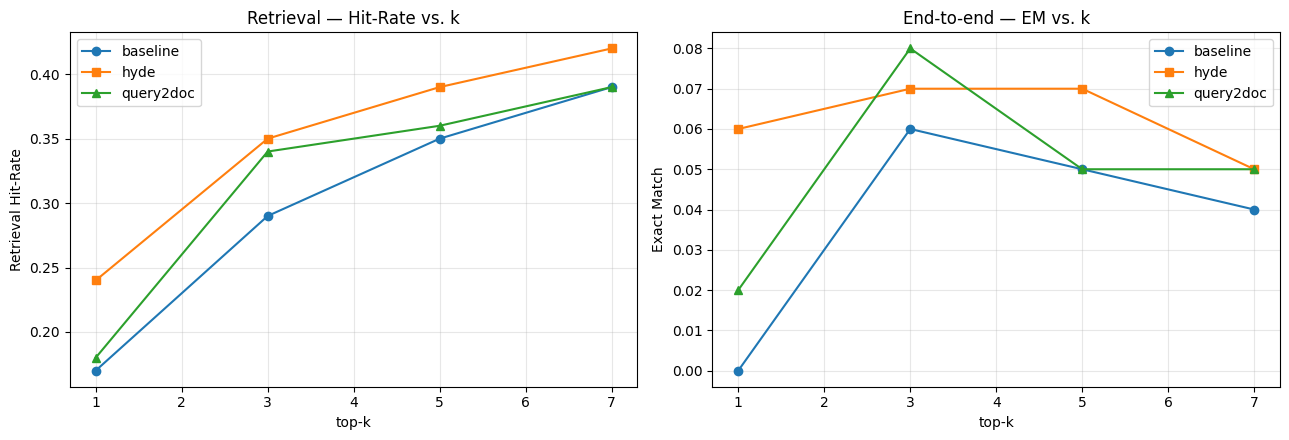

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ks = [1, 3, 5, 7]
for method, marker in [('baseline', 'o'), ('hyde', 's'), ('query2doc', '^')]:
    axes[0].plot(ks, [topk_grid[(method, k)]['retrieval_hit_rate'] for k in ks],
                  marker=marker, label=method)
    axes[1].plot(ks, [topk_grid[(method, k)]['exact_match']        for k in ks],
                  marker=marker, label=method)
axes[0].set_xlabel('top-k'); axes[0].set_ylabel('Retrieval Hit-Rate');  axes[0].set_title('Retrieval — Hit-Rate vs. k')
axes[1].set_xlabel('top-k'); axes[1].set_ylabel('Exact Match');         axes[1].set_title('End-to-end — EM vs. k')
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## 11 · Bias diagnostic — *real* mitigation vs. *apparent* mitigation

Goyal et al. 2026 show that aggregate metric improvements can hide two very different mechanisms:
- **Decorrelation-based** reduction (genuine): the retriever's score becomes *independent* of the surface feature.
- **Variance-based** reduction (apparent): the surface-feature dependency stays, but score variance increases enough that the dependency is no longer detectable by a paired-t test.

We can't reproduce ColDeR's treatment-control pairs without their controlled corpus, but we *can* run the same correlation-based diagnostic on our NQ Open runs: do HyDE / Query2doc / Rewrite reduce the Spearman correlation between the top-1 FAISS score and surface features (chunk length, query-chunk Jaccard, answer position, query-term repetition)?

Smaller `|ρ|` → less surface-feature reliance → genuine mitigation. Same `|ρ|` with better EM → variance-based mitigation (cosmetic).

In [25]:
from bias_analysis import feature_score_correlations, retrieved_chunk_stats

by_method = {
    'Baseline':  baseline_records,
    'HyDE':      hyde_records,
    'Query2doc': q2d_records,
    'Rewrite':   rw_records,
}

rho_rows, stat_rows = [], []
for name, recs in by_method.items():
    rho_rows.append({'Method': name, **feature_score_correlations(recs)})
    stat_rows.append({'Method': name, **retrieved_chunk_stats(recs)})

print('── Spearman ρ between top-1 score and surface features ─────────────────')
print('(0 = no surface-feature reliance; large |ρ| = retriever rewards surface feature)\n')
rho_df = pd.DataFrame(rho_rows).set_index('Method')
display(rho_df)

print('\n── Retrieved-chunk statistics (sanity check) ───────────────────────────')
stat_df = pd.DataFrame(stat_rows).set_index('Method')
display(stat_df)

── Spearman ρ between top-1 score and surface features ─────────────────
(0 = no surface-feature reliance; large |ρ| = retriever rewards surface feature)



,brevity_rho,literal_rho,position_rho,repetition_rho,n
Method,,,,,
Baseline,-0.142730,0.278668,0.102941,0.313423,100
HyDE,-0.124368,0.411377,0.178261,0.284536,100
Query2doc,-0.003396,0.367525,0.282891,0.309895,100
Rewrite,-0.066679,0.341290,0.093506,0.185227,100



── Retrieved-chunk statistics (sanity check) ───────────────────────────


,n_chunks,mean_chunk_len_tokens,mean_query_chunk_jaccard,mean_top1_score,std_top1_score
Method,,,,,
Baseline,500,209.104,0.039081,0.564566,0.064500
HyDE,500,234.808,0.033921,0.644123,0.082226
Query2doc,500,225.482,0.035420,0.634290,0.076638
Rewrite,500,207.978,0.038928,0.558810,0.062746


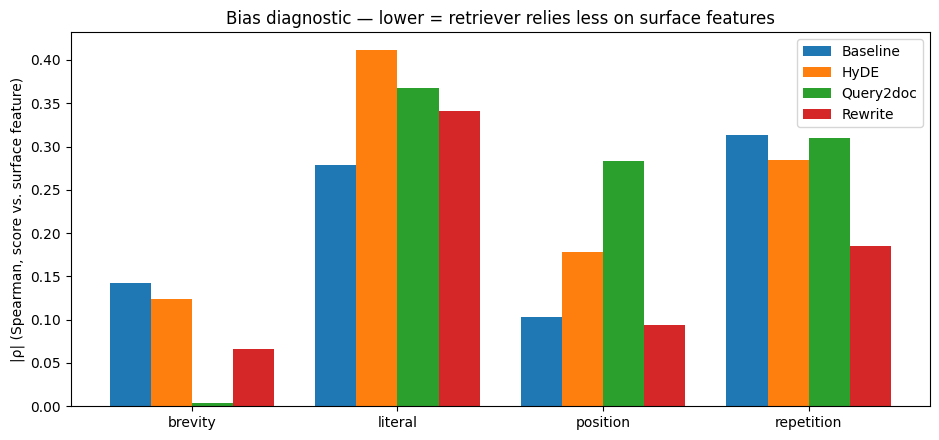

In [26]:
# Plot |ρ| reduction per surface feature, vs. baseline
features = ['brevity_rho', 'literal_rho', 'position_rho', 'repetition_rho']
fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(features))
width = 0.20
for i, name in enumerate(by_method.keys()):
    vals = [abs(rho_df.loc[name, f]) for f in features]
    ax.bar(x + (i - 1.5) * width, vals, width=width, label=name)
ax.set_xticks(x); ax.set_xticklabels([f.replace('_rho', '') for f in features])
ax.set_ylabel('|ρ| (Spearman, score vs. surface feature)')
ax.set_title('Bias diagnostic — lower = retriever relies less on surface features')
ax.legend(); plt.tight_layout(); plt.show()

**Reading the diagnostic.**

Goyal et al. 2026 report (their Table 4, averaged across 6 retrievers including contriever-msmarco) that:

- **HyDE** and **Query2doc** *increase* `|ρ_brevity|` — they shift the retrieval target towards long pseudo-docs that match long Wikipedia chunks, i.e. they correct the dense retriever's preference for short chunks. We expect to see the same direction on our slice.
- **Simple rewriting** *slightly increases* `|ρ_literal|` — the LLM tends to canonicalise the query into "retrieval-friendly" vocabulary that overlaps with the document, which is a textbook *variance-based* reduction: better EM, but the retriever still relies on lexical overlap.
- All methods *increase* `|ρ_repetition|`: pseudo-docs naturally repeat the query's named entities, so the retriever keeps rewarding chunks with high entity repetition.

Whether our N=100 run reproduces these magnitudes will be one of the milestone-3 deepenings — N=100 is at the lower end of statistical power for ρ-style diagnostics.

---
## 12 · Case study — failure modes

Pick a few questions where the baseline fails and see whether HyDE / Query2doc / Rewrite recover (and vice versa). We use the saved per-query records so the comparison is fully aligned.

In [27]:
from evaluate import exact_match

def em(r): return exact_match(r['prediction'], r['gold_answers'])

rows = []
for i in range(N_QUESTIONS):
    rows.append({
        'idx':       i,
        'question':  baseline_records[i]['question'],
        'gold':      ' / '.join(baseline_records[i]['gold_answers']),
        'baseline':  baseline_records[i]['prediction'],
        'hyde':      hyde_records[i]['prediction'],
        'query2doc': q2d_records[i]['prediction'],
        'rewrite':   rw_records[i]['prediction'],
        'baseline_em':  em(baseline_records[i]),
        'hyde_em':      em(hyde_records[i]),
        'query2doc_em': em(q2d_records[i]),
        'rewrite_em':   em(rw_records[i]),
    })
preds_df = pd.DataFrame(rows)

print('── Cases where a rewriting method RECOVERS where baseline failed ──')
rec = preds_df[(preds_df['baseline_em'] == 0) &
               ((preds_df['hyde_em'] == 1) | (preds_df['query2doc_em'] == 1) | (preds_df['rewrite_em'] == 1))]
rec[['question', 'gold', 'baseline', 'hyde', 'query2doc', 'rewrite']].head(8)

── Cases where a rewriting method RECOVERS where baseline failed ──


,question,gold,baseline,hyde,query2doc,rewrite
0,when was the last time anyone was on the moon,14 December 1972 UTC / December 1972,December 1972\n\n[Note: While the question ask...,December 1972,"December 7, 1972","December 7, 1972"
2,how many seasons of the bastard executioner ar...,one / one season,"The context provided does not mention ""The Bas...",The context does not provide information about...,The context provided does not mention The Bast...,One
18,who had a baby at 100 in the bible,Sarah / Abraham,"Abraham, when he had Isaac.","Abraham, according to the context provided, ha...",Abraham,Abraham
41,i was a great islamic scholar and mathematicia...,Omar Khayyam,Unknown,Omar Khayyam,Unknown,Unknown
65,when did houston go to the american league,2013,The Houston Astros went to the American League...,Houston went to the American League in 2013.,2013,The Houston Astros went to the American League...
78,who captained the first european ship to sail ...,Bartolomeu Dias,Vasco da Gama,Bartolomeu Dias,Bartolomeu Dias,Bartolomeu Dias\n\n(Note: The context does not...


In [28]:
print('── Cases where rewriting HURTS (baseline correct, methods wrong) ──')
regr = preds_df[(preds_df['baseline_em'] == 1) &
                ((preds_df['hyde_em'] == 0) | (preds_df['query2doc_em'] == 0) | (preds_df['rewrite_em'] == 0))]
regr[['question', 'gold', 'baseline', 'hyde', 'query2doc', 'rewrite']].head(8)

── Cases where rewriting HURTS (baseline correct, methods wrong) ──


,question,gold,baseline,hyde,query2doc,rewrite
39,who has the power (judicial) to make decisions...,judges,Judges,Judges,Judges,Judges have the power to make decisions in cou...
51,what is the name of the main artery which take...,The aorta / aorta,The aorta,The aorta,The aorta,The main artery that takes blood from the hear...
62,where does the path train stop in newark,Newark Penn Station,Newark Penn Station,Newark Penn Station,The context does not provide information on th...,Newark Penn Station


---
## 13 · Conclusion & next steps

**Summary of this notebook.** Using shared baseline components only (the FAISS index, the contriever encoder, `evaluate.py`, and the Mistral reader prompt), we implemented and evaluated three query-stage rewriting methods on NQ Open:

1. **HyDE** (Gao et al. 2022) — pseudo-doc *replaces* the query embedding.
2. **Query2doc** (Wang et al. 2023) — pseudo-doc *expands* the query.
3. **Rewrite** (Ma et al. 2023, single-query variant) — LLM rewrites the question.

All three differ only in **what is fed to the retriever**; the reader prompt, the embedder, the FAISS index, and the evaluation metrics are held constant against `code/baseline/`. The code lives in `code/p4_querystage/` and the per-method outputs are persisted in `/scratch/results/p4/`.

**Planned for milestone 3 (June 7).**
- Scale to the full NQ validation split (≈3.6k) to tighten the ρ-statistics.
- Replicate the ColDeR controlled-pair diagnostic from Goyal et al. 2026 on our own paired NQ examples (we have the gold answers to construct treatment/control pairs).
- Side-by-side error analysis with P1 (selective retrieval): when the P1 router *skips* retrieval, do query-stage methods make matters worse?
- Combined ablation: HyDE-on-rewrite (rewrite first, then HyDE the rewritten query) — does layering interact?
- Add a `proposition`-style chunking variant from P3 to test whether finer-grained chunks reduce the brevity-bias correlation.